# 03 — Resultados

Resume los resultados de cada etapa del pipeline a partir de las métricas guardadas en `experiments/` y muestra el pipeline completo funcionando sobre fotos de campo CEML.

- No entrena nada: usa los pesos versionados en `models/` y las fotos de `data/ceml/`.
- Corre en CPU en un par de minutos, con las dependencias de `requirements.txt`.
- El detalle de cada experimento está en [experiments/README.md](../experiments/README.md) y el motivo de cada decisión en [docs/decisiones.md](../docs/decisiones.md).

In [1]:
import csv
import json
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EXP = ROOT / "experiments"


def load(path):
    return json.loads((EXP / path).read_text(encoding="utf-8"))


pd.set_option("display.precision", 3)

## 1. Segmentación del visor

Métricas de máscara de YOLOv8n-seg en el test de Toloka y en las 324 fotos CEML (dominio real), calculadas con Ultralytics. A: solo Toloka; B: Toloka + water-meter-dataset con el visor derivado de los dígitos; C: B a 1024 px. Lo que más importa para el pipeline es el **recall en CEML**: un visor no detectado es una lectura perdida.

In [2]:
seg = {"A: Toloka, 640 px": "toloka_yolov8n_seg",
       "B: Toloka + yfzw4, 640 px": "toloka_yfzw4_yolov8n_seg",
       "C: Toloka + yfzw4, 1024 px": "toloka_yfzw4_yolov8n_seg_1024"}
rows = []
for name, exp in seg.items():
    e = load(f"{exp}/eval.json")
    rows.append({"configuración": name,
                 "Toloka mAP50-95": e["toloka_test"]["mask_map50_95"],
                 "CEML mAP50": e["ceml"]["mask_map50"],
                 "CEML mAP50-95": e["ceml"]["mask_map50_95"],
                 "CEML recall": e["ceml"]["mask_recall"],
                 "CPU (ms)": e["cpu_latency_ms"]})
pd.DataFrame(rows).set_index("configuración")

,Toloka mAP50-95,CEML mAP50,CEML mAP50-95,CEML recall,CPU (ms)
configuración,,,,,
"A: Toloka, 640 px",0.877,0.858,0.429,0.867,24.1
"B: Toloka + yfzw4, 640 px",0.847,0.937,0.434,0.910,24.2
"C: Toloka + yfzw4, 1024 px",0.901,0.940,0.401,0.931,51.4


**YOLOv8n-seg contra Mask R-CNN** (mismos datos que B). Ultralytics y torchvision no calculan el mAP igual, así que las dos se comparan con pycocotools (`scripts/evaluate_seg_coco.py`). La latencia de esta tabla se midió en la misma máquina de Kaggle para las dos.

In [3]:
rows = []
for name, exp in {"YOLOv8n-seg (B)": "toloka_yfzw4_yolov8n_seg", "Mask R-CNN R50-FPN": "toloka_yfzw4_maskrcnn"}.items():
    e = load(f"{exp}/eval_coco.json")
    rows.append({"arquitectura": name,
                 "Toloka máscara AP50-95": e["toloka_test"]["mask_ap50_95"],
                 "CEML máscara AP50": e["ceml"]["mask_ap50"],
                 "CEML máscara AP50-95": e["ceml"]["mask_ap50_95"],
                 "CEML caja AP50": e["ceml"]["box_ap50"],
                 "CPU (ms)": e["cpu_latency_ms"]})
pd.DataFrame(rows).set_index("arquitectura")

,Toloka máscara AP50-95,CEML máscara AP50,CEML máscara AP50-95,CEML caja AP50,CPU (ms)
arquitectura,,,,,
YOLOv8n-seg (B),0.847,0.908,0.359,0.948,85.3
Mask R-CNN R50-FPN,0.843,0.864,0.262,0.960,1771.1


## 2. Detección de dígitos

Test de water-meter-dataset sobre el visor rectificado (656 recortes, clases `0`–`9`).

,map50,map50_95,precision,recall
modelo,,,,
digits_yolov8n,0.983,0.687,0.962,0.961
digits_yolo11n,0.984,0.694,0.968,0.955


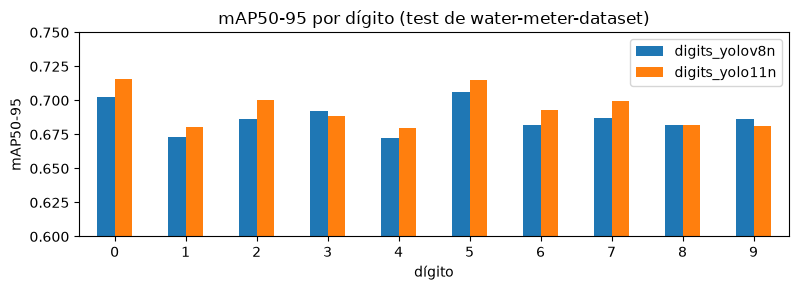

In [4]:
rows, per_class = [], {}
for name in ["digits_yolov8n", "digits_yolo11n"]:
    e = load(f"{name}/eval.json")
    rows.append({"modelo": name, **e["test"]})
    per_class[name] = e["map50_95_por_clase"]
display(pd.DataFrame(rows).set_index("modelo"))

ax = pd.DataFrame(per_class).plot.bar(figsize=(8, 3), ylim=(0.6, 0.75), rot=0)
ax.set_xlabel("dígito")
ax.set_ylabel("mAP50-95")
ax.set_title("mAP50-95 por dígito (test de water-meter-dataset)")
plt.tight_layout()

## 3. Formato del medidor (m³ y fracción)

MobileNetV3-small con transfer learning clasifica el formato (`<dígitos de m³>_<dígitos de fracción>`) a partir del visor con su entorno. Validación cruzada estratificada de 5 folds sobre las fotos CEML: cada foto se predice con un modelo que no la vio.

Fotos: 320 | exactitud: 98.4% | F1 macro: 0.954


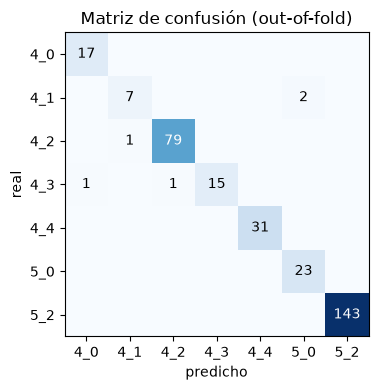

In [5]:
cv = load("meter_layout_mnv3s/cv.json")
print(f"Fotos: {cv['images']} | exactitud: {cv['accuracy']:.1%} | F1 macro: {cv['macro_f1']:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cv["confusion"], cmap="Blues")
ax.set_xticks(range(len(cv["classes"])), cv["classes"])
ax.set_yticks(range(len(cv["classes"])), cv["classes"])
for i, row in enumerate(cv["confusion"]):
    for j, n in enumerate(row):
        if n:
            ax.text(j, i, n, ha="center", va="center", color="white" if n > 50 else "black")
ax.set_xlabel("predicho")
ax.set_ylabel("real")
ax.set_title("Matriz de confusión (out-of-fold)")
plt.tight_layout()

## 4. Lectura de punta a punta en CEML

`scripts/evaluate_pipeline.py` sobre las 323 fotos verificadas y legibles. Todas las configuraciones usan la misma segmentación del visor (B).

- **Exacta**: la lectura completa coincide, con el punto y los ceros.
- **m³ exactos**: coincide la parte entera, que es lo que se factura.
- **CER**: errores de edición entre dígitos / dígitos reales.

El experimento principal es **A contra C**: si rectificar el visor mejora la lectura frente a un recorte por caja.

,exacta,m3_exactos,cer,sin_lectura,cobertura_confianza,exacta_con_confianza
configuracion,,,,,,
rectificado + YOLOv8n + clasificador,0.712,0.78,0.121,0.081,0.807,0.831
rectificado + YOLOv8n + color,0.547,0.582,0.121,0.081,0.807,0.631
caja + YOLOv8n + clasificador,0.636,0.718,0.176,0.124,0.737,0.828
rectificado + YOLO11n + clasificador,0.614,0.734,0.151,0.081,0.81,0.742
rectificado + EasyOCR + clasificador,0.003,0.006,0.898,0.164,0.076,0.042


Latencia del pipeline final (A) en CPU: 73.9 ms por foto


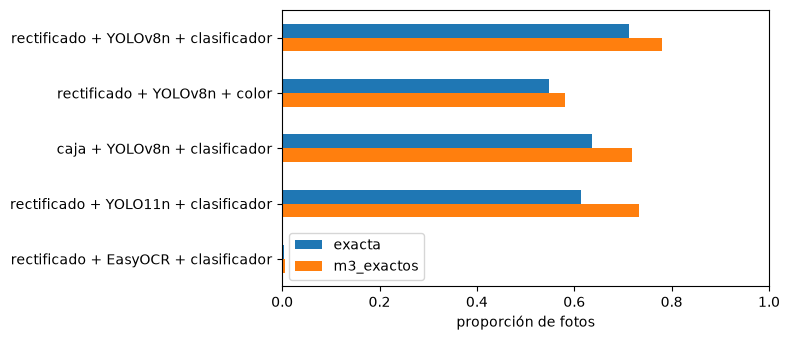

In [6]:
results = load("pipeline_ceml/results.json")
latency = results.pop("latencia_cpu_ms")
table = pd.DataFrame(results).T.set_index("configuracion")
display(table[["exacta", "m3_exactos", "cer", "sin_lectura", "cobertura_confianza", "exacta_con_confianza"]])
print(f"Latencia del pipeline final (A) en CPU: {latency} ms por foto")

ax = table[["exacta", "m3_exactos"]].plot.barh(figsize=(8, 3.5), xlim=(0, 1))
ax.invert_yaxis()
ax.set_xlabel("proporción de fotos")
ax.set_ylabel("")
plt.tight_layout()

**Exactitud por formato de medidor** (configuración A). Cruza las predicciones con el formato anotado en `data/ceml/readings.csv`.

In [7]:
preds = pd.read_csv(EXP / "pipeline_ceml/predictions.csv", dtype=str).fillna("")
sheet = pd.read_csv(ROOT / "data/ceml/readings.csv", dtype=str).fillna("")
df = preds.merge(sheet[["file", "modelo"]], on="file")
df["formato"] = df["modelo"].str.extract(r"_(\d_\d)$")[0].fillna("sin modelo")
df = df[~df["reading"].str.endswith(".")]  # fracción ilegible: no cuenta para la lectura exacta
df["exacta"] = df["A"] == df["reading"]
df.groupby("formato")["exacta"].agg(fotos="size", exacta="mean").sort_values("fotos", ascending=False)

,fotos,exacta
formato,,
5_2,142,0.852
4_2,79,0.734
4_4,31,0.484
5_0,23,0.522
4_0,17,0.588
4_3,11,0.545
4_1,9,0.333
5_3,2,0.000
sin modelo,2,0.000


## 5. El pipeline paso a paso

Corre el pipeline final sobre algunas fotos CEML: segmentación del visor (contorno verde), visor rectificado con los dígitos detectados y la lectura contra la verdad de campo. Se eligen al azar (semilla fija) tres aciertos y tres errores de la configuración A.

El formato de cada foto sale de la predicción out-of-fold del clasificador (`oof.csv`), igual que en la evaluación: el modelo final de `models/` se entrenó con estas mismas fotos.

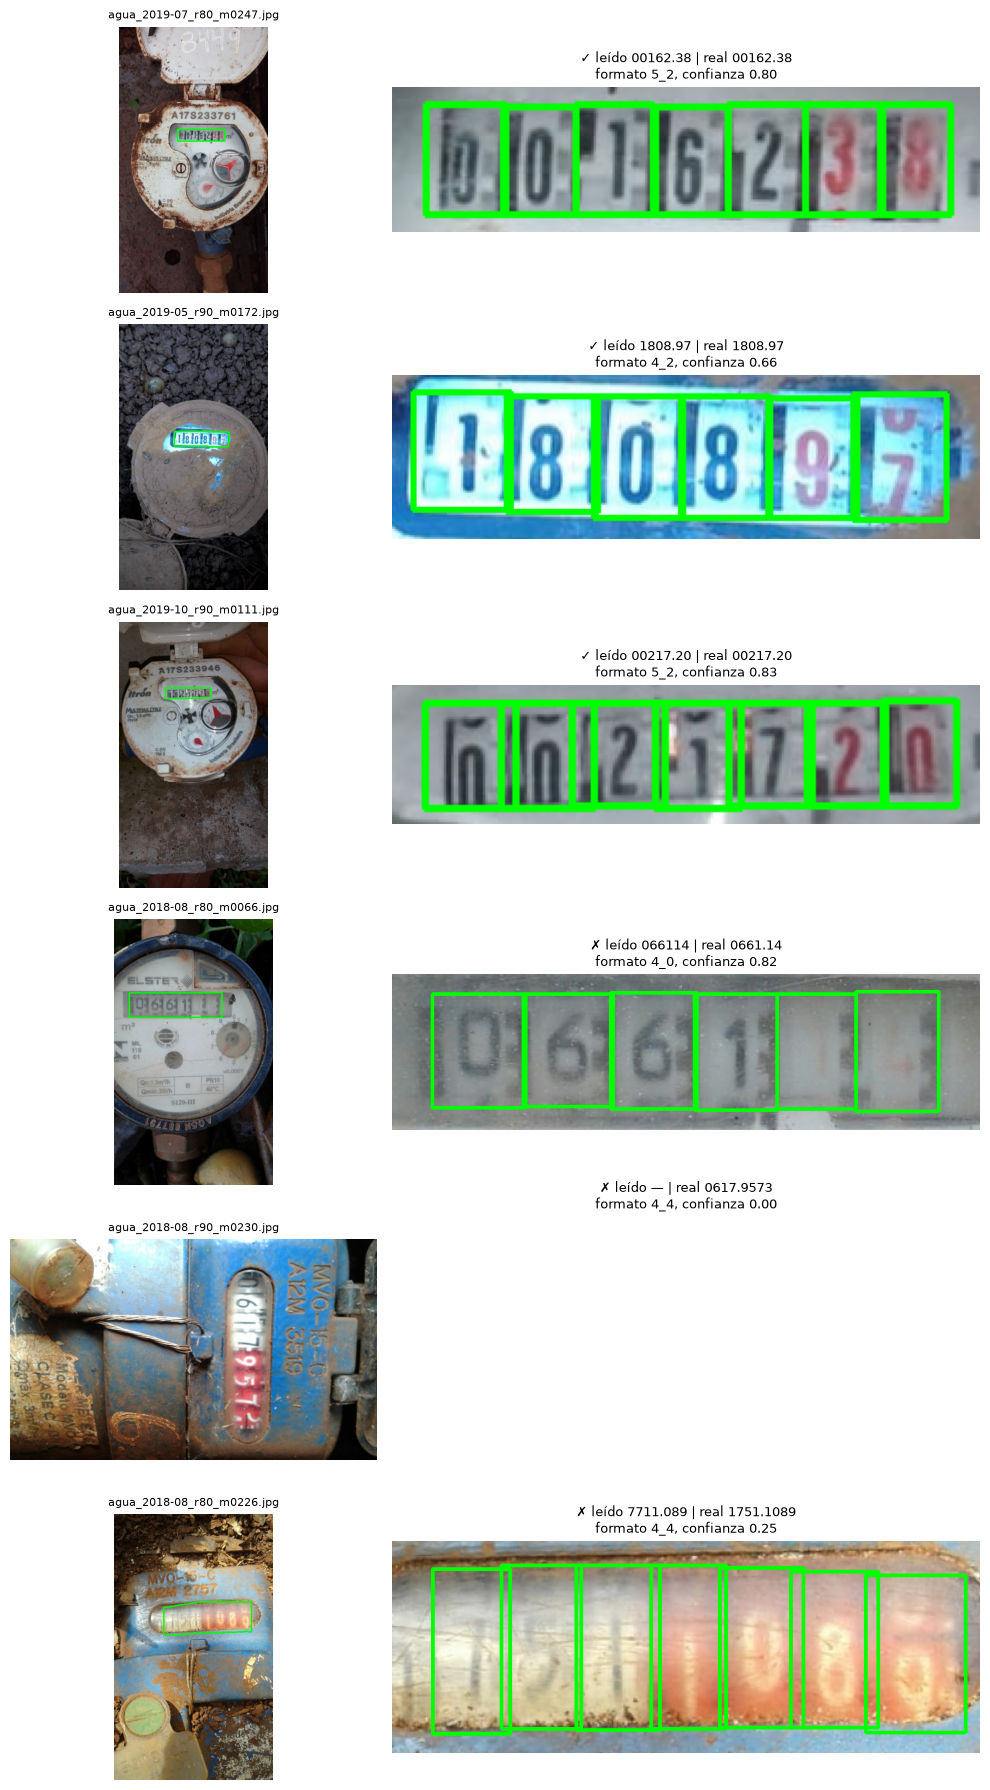

In [8]:
from meter_reader.pipeline import MIN_MODEL_PROB, load_models, read_meter

segment, detect = load_models("models/toloka_yfzw4_yolov8n_seg.pt", "models/digits_yolov8n.pt", device="cpu")
with (EXP / "meter_layout_mnv3s/oof.csv").open(newline="", encoding="utf-8") as f:
    oof = {r["file"]: (r["predicho"], float(r["probabilidad"])) for r in csv.DictReader(f)}

rng = np.random.default_rng(0)
hits = df[df["exacta"]]["file"].to_numpy()
misses = df[~df["exacta"]]["file"].to_numpy()
sample = [*rng.choice(hits, 3, replace=False), *rng.choice(misses, 3, replace=False)]
truth = dict(zip(df["file"], df["reading"]))


def show(file, axes):
    image = cv2.imread(str(ROOT / "data/ceml/images" / file))
    label = oof.get(file, ("", 0.0))
    result = read_meter(image, segment, detect, lambda _img, label=label: label)
    overlay = image.copy()
    if result.polygon is not None:
        cv2.polylines(overlay, [result.polygon.astype(np.int32)], True, (0, 255, 0), 6)
    axes[0].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[0].set_title(file, fontsize=8)
    if result.crop is not None:
        crop = result.crop.copy()
        for d in result.reading.digits:
            cv2.rectangle(crop, (int(d.x1), int(d.y1)), (int(d.x2), int(d.y2)), (0, 255, 0), 2)
        axes[1].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ok = "✓" if result.reading.formatted == truth[file] else "✗"
    axes[1].set_title(f"{ok} leído {result.reading.formatted or '—'} | real {truth[file]}\n"
                      f"formato {label[0] if label[1] >= MIN_MODEL_PROB else 'por color'}, "
                      f"confianza {result.reading.confidence:.2f}", fontsize=9)
    for ax in axes:
        ax.axis("off")


fig, grid = plt.subplots(len(sample), 2, figsize=(10, 3 * len(sample)), gridspec_kw={"width_ratios": [1, 1.6]})
for file, axes in zip(sample, grid):
    show(file, axes)
plt.tight_layout()

## 6. Conclusiones

- **Segmentar y rectificar el visor mejora la lectura** frente al recorte por caja (A contra C): más lecturas exactas, menor CER y menos fotos sin lectura.
- **El clasificador de formato es lo que más aporta a los m³** (A contra B): con los mismos dígitos, decide dónde va el punto.
- **La métrica de detección no anticipa la de punta a punta**: YOLOv8n y YOLO11n empatan en el test de dígitos, pero en CEML YOLOv8n lee mejor.
- **Un OCR genérico no sirve para rodillos** (E): lee las barras entre rodillos y los números a medio girar.
- **La confianza sirve de filtro**: las lecturas con confianza baja se mandan a revisión manual en la app.